## 1.1 	Library imports

In [6]:
# Data manipulation
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset acquisition
from ucimlrepo import fetch_ucirepo

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)

print("All libraries imported successfully!")

All libraries imported successfully!


## 1.2 	Dataset acquisition

In [7]:
from ucimlrepo import fetch_ucirepo

# Fetch Combined Cycle Power Plant dataset
dataset = fetch_ucirepo(id=294)

print("Dataset downloaded successfully!")

Dataset downloaded successfully!


## 	1.3 Separate X and y

In [8]:
X = dataset.data.features
y = dataset.data.targets

print("Features:")
display(X.head())

print("Target:")
display(y.head())

Features:


,AT,V,AP,RH
0,14.96,41.76,1024.07,73.17
1,25.18,62.96,1020.04,59.08
2,5.11,39.40,1012.16,92.14
3,20.86,57.32,1010.24,76.64
4,10.82,37.50,1009.23,96.62


Target:


,PE
0,463.26
1,444.37
2,488.56
3,446.48
4,473.90


## 1.4 Combine dataset

In [9]:
import pandas as pd
df = pd.concat([X, y], axis=1)

df.head()


,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


## 1.5 Saving the Dataset

In [10]:
import os

os.makedirs("../data", exist_ok=True)

df.to_csv("../data/ccpp.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


## 1.6 Dataset Overview

In [11]:
print("Dataset Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (9568, 5)

Columns:
['AT', 'V', 'AP', 'RH', 'PE']

Data Types:
AT    float64
V     float64
AP    float64
RH    float64
PE    float64
dtype: object


## 1.7 Missing-Value Analysis

In [13]:
# Count missing values in each column
print(df.isnull().sum())

missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)

AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64
AT   0.00
V    0.00
AP   0.00
RH   0.00
PE   0.00
dtype: float64


## 1.8 Duplicate Analysis

In [14]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)


Number of duplicate rows: 41


## 1.9 Data Cleaning

In [15]:
# Create a cleaned copy of the dataset

df_clean = df.drop_duplicates().reset_index(drop=True)

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("Duplicates remaining:", df_clean.duplicated().sum())

Original dataset shape: (9568, 5)
Cleaned dataset shape: (9527, 5)
Duplicates remaining: 0


## 1.10 Descriptive Statistics

In [16]:
df_clean.describe()

,AT,V,AP,RH,PE
count,9527.00,9527.00,9527.00,9527.00,9527.00
mean,19.66,54.29,1013.24,73.33,454.34
std,7.44,12.69,5.94,14.61,17.04
min,1.81,25.36,992.89,25.56,420.26
25%,13.53,41.74,1009.09,63.38,439.75
50%,20.35,52.08,1012.92,75.00,451.52
75%,25.71,66.51,1017.20,84.85,468.37
max,37.11,81.56,1033.30,100.16,495.76


## 1.11 Univariate Analysis

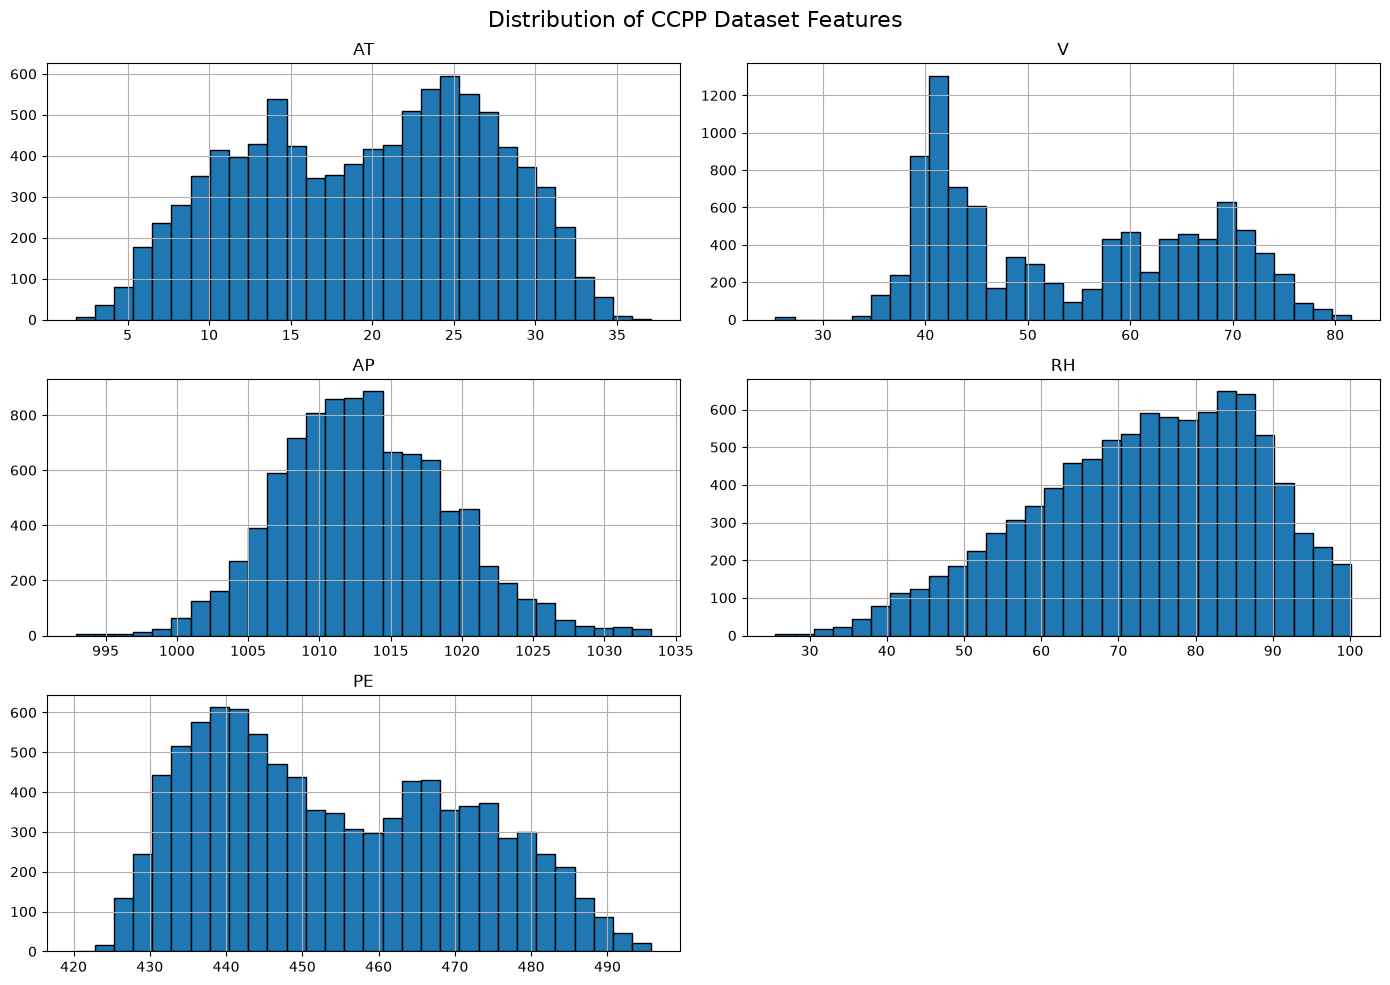

In [17]:
# Plot distribution of all numerical features

df_clean.hist(
    figsize=(14, 10),
    bins=30,
    edgecolor='black'
)

plt.suptitle("Distribution of CCPP Dataset Features", fontsize=16)

plt.tight_layout()
plt.show()

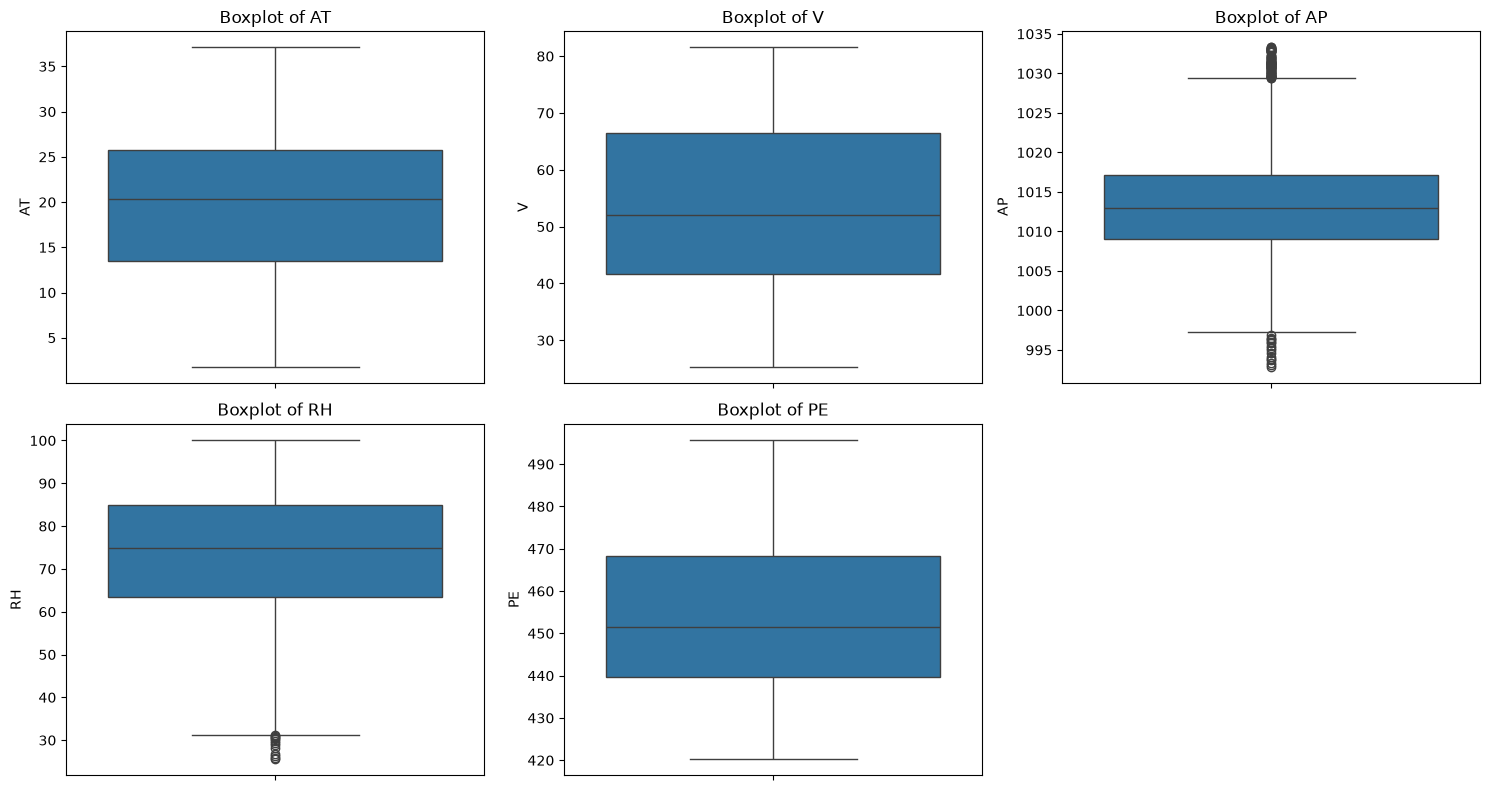

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

columns = ['AT', 'V', 'AP', 'RH', 'PE']

for col, ax in zip(columns, axes.flatten()):
    sns.boxplot(y=df_clean[col], ax=ax)
    ax.set_title(f'Boxplot of {col}')
    
# Remove unused subplot
fig.delaxes(axes[1, 2])

plt.tight_layout()
plt.show()

## 1.12 Bivariate Analysis

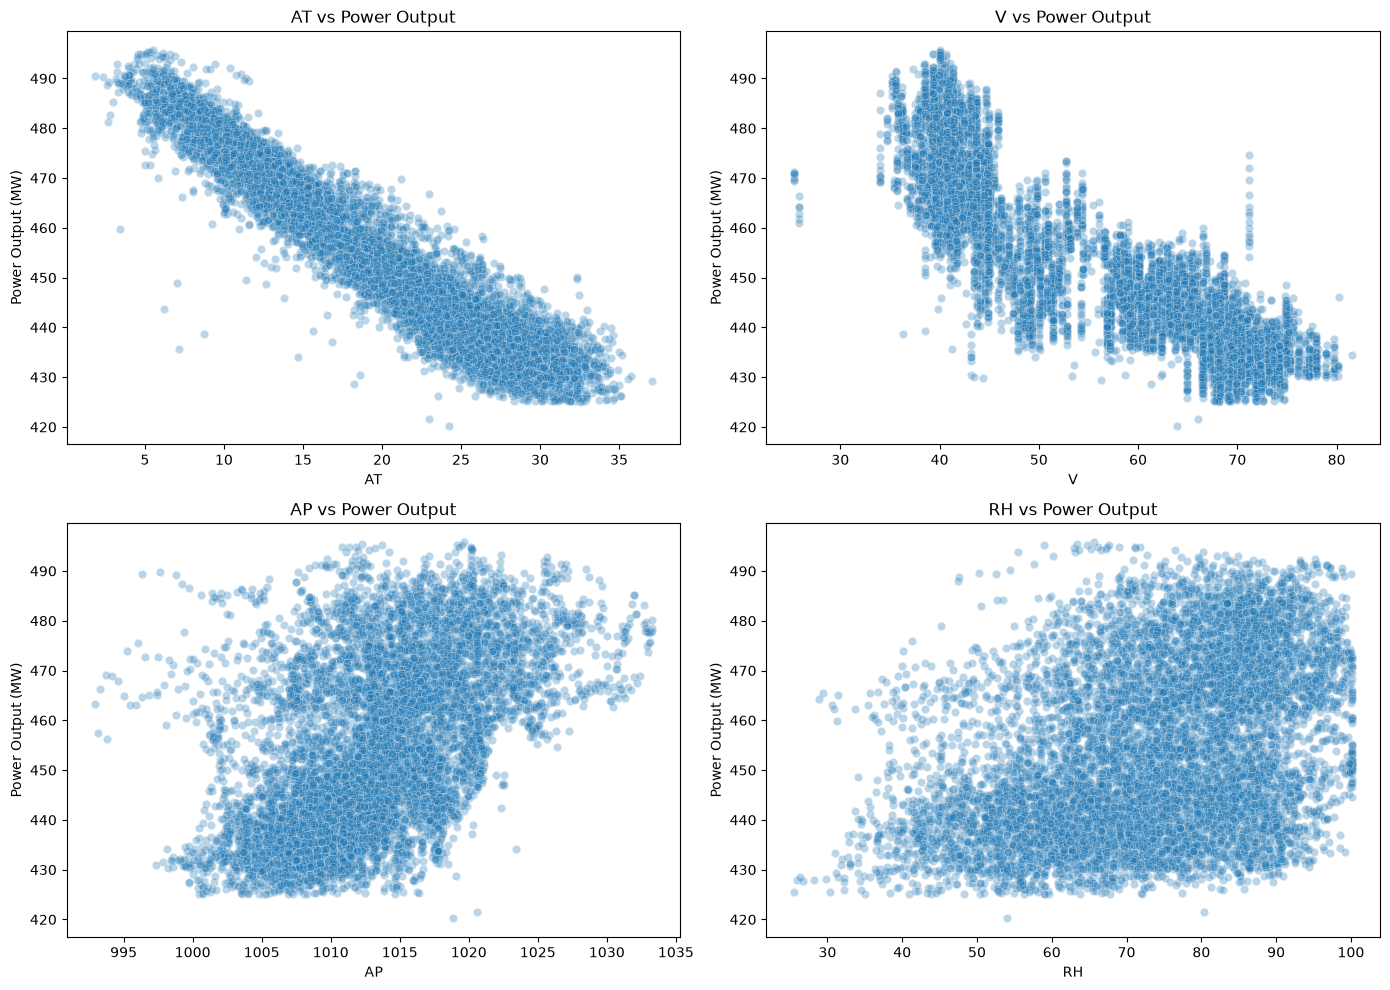

In [20]:
# Relationship between input features and power output

features = ['AT', 'V', 'AP', 'RH']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for feature, ax in zip(features, axes.flatten()):
    sns.scatterplot(
        data=df_clean,
        x=feature,
        y='PE',
        alpha=0.3,
        ax=ax
    )
    
    ax.set_title(f'{feature} vs Power Output')
    ax.set_xlabel(feature)
    ax.set_ylabel('Power Output (MW)')

plt.tight_layout()
plt.show()

## 1.13 Correlation Analysis

In [21]:
correlations = df_clean.corr()['PE'].drop('PE')

print(correlations.sort_values(ascending=False))

AP    0.52
RH    0.39
V    -0.87
AT   -0.95
Name: PE, dtype: float64


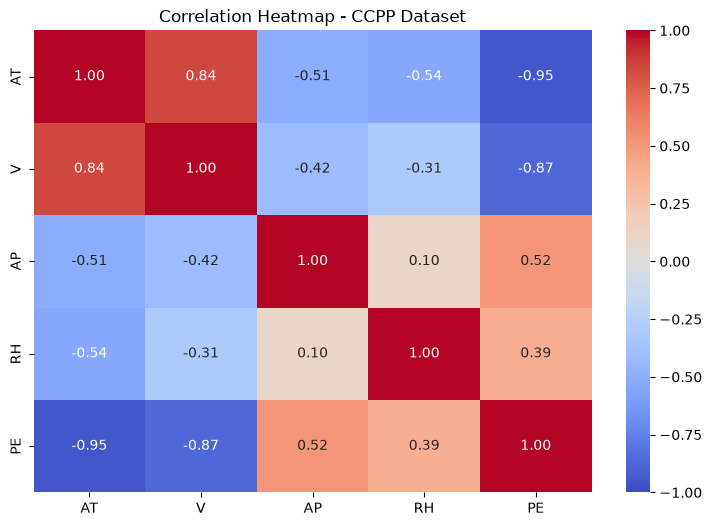

In [22]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    df_clean.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap - CCPP Dataset")
plt.show()

# 2. Feature Engineering and Data Preparation

## 2.1 Feature and Target Separation

In [23]:
# Separate independent and dependent variables

X = df_clean.drop('PE', axis=1)
y = df_clean['PE']

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())

Feature shape: (9527, 4)
Target shape: (9527,)


,AT,V,AP,RH
0,14.96,41.76,1024.07,73.17
1,25.18,62.96,1020.04,59.08
2,5.11,39.40,1012.16,92.14
3,20.86,57.32,1010.24,76.64
4,10.82,37.50,1009.23,96.62


0   463.26
1   444.37
2   488.56
3   446.48
4   473.90
Name: PE, dtype: float64

## 2.2 Train-Test Split

In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (7621, 4)
Testing features: (1906, 4)
Training target: (7621,)
Testing target: (1906,)


## 2.3 Preprocessing Strategy

We will use StandardScaler for Linear Regression to ensure that
all input features are on a comparable scale.

Tree-based models such as Random Forest and Gradient Boosting
do not require feature scaling.

Preprocessing will be implemented inside Scikit-learn Pipelines
to prevent data leakage during cross-validation.

# 3. Model Training and Comparison

## 3.1 Model Selection

### Objective

We will compare three regression algorithms to identify the most suitable model for predicting electrical power output (PE).

### Selected Algorithms

| Algorithm | Purpose | Expected Strength |
|---|---|---|
| Linear Regression | Baseline model | Simple and interpretable |
| Random Forest Regressor | Ensemble learning (Bagging) | Captures nonlinear relationships |
| Gradient Boosting Regressor | Ensemble learning (Boosting) | Captures complex patterns through sequential learning |

### Model Comparison Strategy

All three models will be evaluated using:

- 5-Fold Cross-Validation
- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- R² Score

The models will be compared using identical training data and evaluation procedures.

The final model will be selected based on cross-validation performance, generalisation ability and computational considerations.

## 3.2 Linear Regression

### 3.2.1 Building the Pipeline

Linear Regression will serve as our baseline model.

We use StandardScaler to standardise input features before training.
A Scikit-learn Pipeline combines scaling and model training to
prevent data leakage during cross-validation.

In [25]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

linear_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LinearRegression())
])

### 3.2.2 Model Training

In [26]:
linear_pipeline.fit(X_train, y_train)

print("Linear Regression trained successfully!")

Linear Regression trained successfully!


### 3.2.3 Predictions

In [27]:
y_pred_lr = linear_pipeline.predict(X_test)

print("Actual values:")
print(y_test.head())

print("\nPredicted values:")
print(y_pred_lr[:5])

Actual values:
1087   463.57
6308   441.31
8021   445.34
9483   465.42
4459   439.06
Name: PE, dtype: float64

Predicted values:
[462.51898394 446.67819631 447.95770234 467.4435959  434.67990705]


### 3.2.4 Baseline Evaluation

In [28]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred_lr)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2 = r2_score(y_test, y_pred_lr)

print("Linear Regression Results")
print("--------------------------")
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

Linear Regression Results
--------------------------
MAE: 3.6214672910209487
RMSE: 4.587499007655297
R2 Score: 0.9283920303369918


## 3.3 Random Forest Regressor

### 3.3.1 Understanding Random Forest

Random Forest is an ensemble learning algorithm based on Decision Trees.

Instead of relying on a single decision tree, it builds multiple trees using different random samples of the training data and random subsets of features.

For regression, the final prediction is obtained by averaging the predictions of all individual trees.

**Mathematical Representation:**

ŷ = (1/N) Σ Tᵢ(x)

Where:
- N = Number of decision trees.
- Tᵢ(x) = Prediction made by the ith tree.
- ŷ = Final predicted output.

**Why Random Forest?**

1. Captures nonlinear relationships.
2. Models interactions between input features.
3. Does not require feature scaling.
4. Reduces variance compared to an individual decision tree through averaging.

We use Random Forest to investigate whether a nonlinear ensemble model can outperform our Linear Regression baseline.

### 3.3.2 Model Pipeline

We use RandomForestRegressor to build an ensemble of decision trees.

Unlike Linear Regression, Random Forest does not require feature scaling because tree-based algorithms split data based on feature values rather than distances.

In [29]:
from sklearn.ensemble import RandomForestRegressor

rf_pipeline = Pipeline([
    ('model', RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

### 3.3.3 Model Training

In [32]:
rf_pipeline.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


### 3.3.4 Cross-Validation

In [33]:
from sklearn.model_selection import cross_validate

scoring = {
    'mae': 'neg_mean_absolute_error',
    'rmse': 'neg_root_mean_squared_error',
    'r2': 'r2'
}

rf_cv = cross_validate(
    rf_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring=scoring,
    n_jobs=-1
)

print("Random Forest Cross-Validation Results")
print("--------------------------------------")

print("Mean MAE:", -rf_cv['test_mae'].mean())
print("Mean RMSE:", -rf_cv['test_rmse'].mean())
print("Mean R2:", rf_cv['test_r2'].mean())

Random Forest Cross-Validation Results
--------------------------------------
Mean MAE: 2.4569945301751184
Mean RMSE: 3.405470013891457
Mean R2: 0.9598100540359538


### 3.3.5 Test Set Evaluation

After cross-validation, we evaluate the trained Random Forest model on the unseen test dataset.

We use three metrics:

- MAE: Average absolute prediction error.
- RMSE: Penalises larger prediction errors.
- R² Score: Measures the proportion of variance explained by the model.

These results will help us compare Random Forest with Linear Regression.

In [34]:
y_pred_rf = rf_pipeline.predict(X_test)

mae_rf = mean_absolute_error(y_test, y_pred_rf)

rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))

r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Results")
print("---------------------")
print("MAE:", mae_rf)
print("RMSE:", rmse_rf)
print("R2 Score:", r2_rf)

Random Forest Results
---------------------
MAE: 2.41526768100735
RMSE: 3.446821897492318
R2 Score: 0.9595752744431597


# 3.4 – Gradient Boosting Regressor.

### 3.4.1 Understanding Gradient Boosting

Gradient Boosting is an ensemble learning algorithm that combines multiple weak learners (decision trees) to create a strong predictive model.

Unlike Random Forest, where trees are trained independently, Gradient Boosting builds trees sequentially.

Each new tree attempts to correct the errors made by the previous ensemble.

**Key Characteristics:**

1. Captures nonlinear relationships.
2. Learns sequentially from previous errors.
3. Combines multiple weak learners.
4. Can achieve high predictive accuracy.
5. Requires careful tuning to prevent overfitting.

**Why Gradient Boosting?**

We use Gradient Boosting to investigate whether sequential ensemble learning can outperform Random Forest and Linear Regression.

### 3.4.2 Model Pipeline

We use GradientBoostingRegressor from Scikit-learn to build our predictive model.

The model combines multiple decision trees sequentially, where each successive tree attempts to reduce the errors of the existing ensemble.

Since Gradient Boosting is tree-based, feature scaling is not required.

In [35]:
from sklearn.ensemble import GradientBoostingRegressor

gb_pipeline = Pipeline([
    ('model', GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

### 3.4.3 Model Training

The Gradient Boosting model is trained using the training dataset.

During training, decision trees are built sequentially, with each new tree attempting to minimise the residual errors of the existing ensemble.

In [36]:
gb_pipeline.fit(X_train, y_train)

print("Gradient Boosting trained successfully!")

Gradient Boosting trained successfully!


### 3.4.4 Cross-Validation

We evaluate the Gradient Boosting model using 5-fold cross-validation.

The training dataset is divided into five subsets. Each subset is used once for validation, while the remaining four subsets are used for training.

We calculate the average MAE, RMSE and R² across all five folds to assess model performance and generalisation ability.

In [37]:
gb_cv = cross_validate(
    gb_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring=scoring,
    n_jobs=-1
)

print("Gradient Boosting Cross-Validation Results")
print("------------------------------------------")

print("Mean MAE:", -gb_cv['test_mae'].mean())
print("Mean RMSE:", -gb_cv['test_rmse'].mean())
print("Mean R2:", gb_cv['test_r2'].mean())

Gradient Boosting Cross-Validation Results
------------------------------------------
Mean MAE: 2.9595213772832425
Mean RMSE: 3.87715029121105
Mean R2: 0.947948400490281


### 3.4.5 Test Set Evaluation

The trained Gradient Boosting model is evaluated on the unseen test dataset.

We calculate MAE, RMSE and R² to assess its predictive performance.

These results will be compared with Linear Regression and Random Forest to identify the most suitable model.

In [38]:
y_pred_gb = gb_pipeline.predict(X_test)

mae_gb = mean_absolute_error(y_test, y_pred_gb)

rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))

r2_gb = r2_score(y_test, y_pred_gb)

print("Gradient Boosting Results")
print("-------------------------")
print("MAE:", mae_gb)
print("RMSE:", rmse_gb)
print("R2 Score:", r2_gb)

Gradient Boosting Results
-------------------------
MAE: 3.006688132838924
RMSE: 3.983519325932256
R2 Score: 0.9460062799501989


## 3.5 Model Comparison

### 3.5.1 Performance Comparison

We compare the three regression algorithms using their test-set evaluation metrics.

The metrics considered are:

- MAE: Measures average absolute prediction error.
- RMSE: Penalises larger prediction errors.
- R²: Measures the proportion of variance explained by the model.

Lower MAE and RMSE indicate better performance, while higher R² indicates better predictive ability.

The comparison helps identify the most suitable algorithm for predicting electrical power output.

In [39]:
comparison = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Random Forest',
        'Gradient Boosting'
    ],
    'MAE': [mae, mae_rf, mae_gb],
    'RMSE': [rmse, rmse_rf, rmse_gb],
    'R2 Score': [r2, r2_rf, r2_gb]
})

comparison = comparison.sort_values(
    by='RMSE'
).reset_index(drop=True)

display(comparison)

,Model,MAE,RMSE,R2 Score
0,Random Forest,2.42,3.45,0.96
1,Gradient Boosting,3.01,3.98,0.95
2,Linear Regression,3.62,4.59,0.93


### 3.5.2 Visual Comparison of Models

We visualise the performance of all three regression algorithms using bar plots.

This makes it easier to compare their MAE, RMSE and R² scores.

For MAE and RMSE, lower values indicate better performance. For R², higher values indicate better performance.

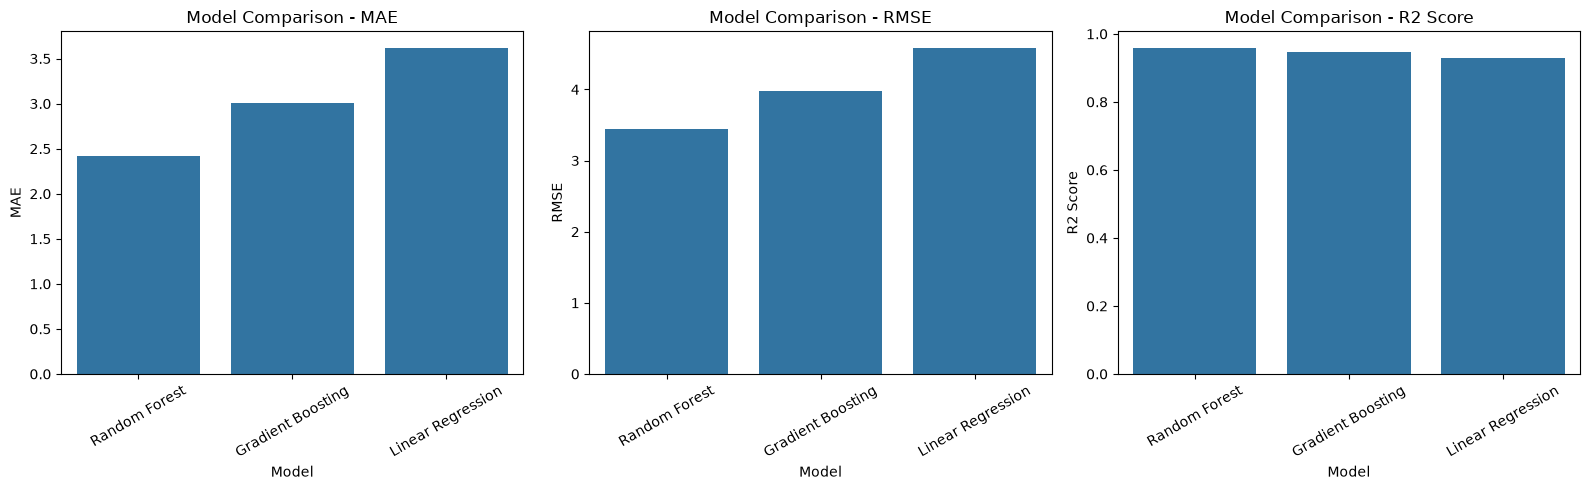

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metrics = ['MAE', 'RMSE', 'R2 Score']

for metric, ax in zip(metrics, axes):
    sns.barplot(
        data=comparison,
        x='Model',
        y=metric,
        ax=ax
    )
    
    ax.set_title(f'Model Comparison - {metric}')
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

## 3.6 Hyperparameter Tuning

### 3.6.1 Random Forest Hyperparameter Tuning

Hyperparameter tuning is performed to identify the optimal model configuration.

We use GridSearchCV to evaluate different combinations of Random Forest hyperparameters through 5-fold cross-validation.

The best configuration is selected based on the lowest cross-validation RMSE.

In [41]:
from sklearn.model_selection import GridSearchCV

In [42]:
param_grid = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [None, 10, 20],
    'model__min_samples_split': [2, 5],
    'model__min_samples_leaf': [1, 2]
}

In [43]:
rf_grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    verbose=1
)

rf_grid.fit(X_train, y_train)

Fitting 5 folds for each of 36 candidates, totalling 180 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [None, 10, ...], 'model__min_samples_leaf': [1, 2], 'model__min_samples_split': [2, 5], 'model__n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multip

In [44]:
print("Best Parameters:")
print(rf_grid.best_params_)

print("\nBest Cross-Validation RMSE:")
print(-rf_grid.best_score_)

Best Parameters:
{'model__max_depth': 20, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 300}

Best Cross-Validation RMSE:
3.384358942854612


### 3.6.2 Evaluation of Tuned Random Forest

The best estimator identified by GridSearchCV is evaluated on the unseen test dataset.

We compare its performance with the original Random Forest model to determine whether hyperparameter tuning improves generalisation.

In [45]:
best_rf = rf_grid.best_estimator_

y_pred_tuned = best_rf.predict(X_test)

mae_tuned = mean_absolute_error(y_test, y_pred_tuned)

rmse_tuned = np.sqrt(mean_squared_error(y_test, y_pred_tuned))

r2_tuned = r2_score(y_test, y_pred_tuned)

print("Tuned Random Forest Results")
print("---------------------------")
print("MAE:", mae_tuned)
print("RMSE:", rmse_tuned)
print("R2 Score:", r2_tuned)

Tuned Random Forest Results
---------------------------
MAE: 2.4122512403339305
RMSE: 3.438201437275279
R2 Score: 0.9597772250962399


### 3.6.3 Original vs Tuned Random Forest

We compare the original Random Forest model with the hyperparameter-tuned version.

This comparison helps determine whether tuning has resulted in measurable improvements in predictive performance.

In [46]:
rf_comparison = pd.DataFrame({
    'Model': ['Original Random Forest', 'Tuned Random Forest'],
    'MAE': [mae_rf, mae_tuned],
    'RMSE': [rmse_rf, rmse_tuned],
    'R2 Score': [r2_rf, r2_tuned]
})

display(rf_comparison)

,Model,MAE,RMSE,R2 Score
0,Original Random Forest,2.42,3.45,0.96
1,Tuned Random Forest,2.41,3.44,0.96


## 3.7 Overfitting Analysis

Overfitting occurs when a model performs very well on training data but performs poorly on unseen testing data.

We compare training and testing errors to assess the generalisation ability of our models.

In [47]:
# Calculate training and testing RMSE

models = {
    'Linear Regression': linear_pipeline,
    'Random Forest': rf_pipeline,
    'Gradient Boosting': gb_pipeline,
    'Tuned Random Forest': best_rf
}

overfitting_results = []

for name, model in models.items():

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
    test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))

    overfitting_results.append({
        'Model': name,
        'Training RMSE': train_rmse,
        'Testing RMSE': test_rmse,
        'Difference': test_rmse - train_rmse
    })

overfitting_df = pd.DataFrame(overfitting_results)

display(overfitting_df)

,Model,Training RMSE,Testing RMSE,Difference
0,Linear Regression,4.55,4.59,0.04
1,Random Forest,1.24,3.45,2.21
2,Gradient Boosting,3.67,3.98,0.31
3,Tuned Random Forest,1.24,3.44,2.20


The overfitting analysis shows that Random Forest models have a significant difference between training and testing errors, indicating some overfitting.

Gradient Boosting demonstrates better generalisation with a smaller difference between training and testing RMSE.

Linear Regression shows the least overfitting but has comparatively higher prediction errors.

Despite some overfitting, the Tuned Random Forest remains the best-performing model based on testing RMSE and R² score.

# 3.8 Feature Importance Analysis

Feature importance analysis is performed using the Tuned Random Forest model to identify the relative contribution of each input feature in predicting electrical power output (PE).

This analysis helps us understand which environmental variables have the greatest influence on power plant performance.

In [48]:
# Extract feature importance from the tuned Random Forest model

best_rf_model = best_rf.named_steps['model']

feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': best_rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

display(feature_importance)

,Feature,Importance
0,AT,0.90
1,V,0.06
2,AP,0.02
3,RH,0.02


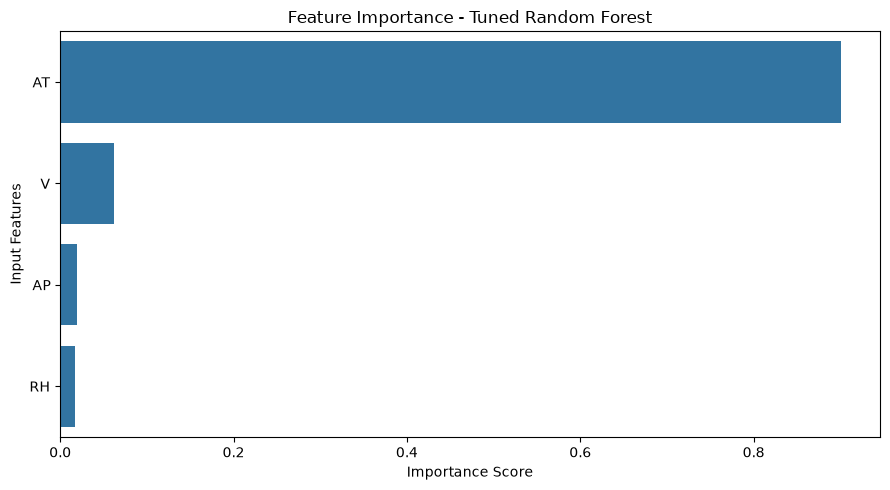

In [49]:
# Plot feature importance

plt.figure(figsize=(9, 5))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title('Feature Importance - Tuned Random Forest')
plt.xlabel('Importance Score')
plt.ylabel('Input Features')

plt.tight_layout()
plt.show()

### Interpretation

The feature importance analysis reveals that Ambient Temperature (AT) is the most influential variable in predicting electrical power output, contributing approximately 90% of the total feature importance.

Exhaust Vacuum (V) is the second most important feature, with an importance score of approximately 0.06.

Ambient Pressure (AP) and Relative Humidity (RH) have relatively smaller contributions, with importance scores of approximately 0.02 each.

These results indicate that Ambient Temperature plays a dominant role in predicting power output, while the remaining variables have comparatively smaller contributions to the Tuned Random Forest model's predictions.

# 3.9 Actual vs Predicted Analysis

The performance of the Tuned Random Forest model is evaluated by comparing actual electrical power output values with the predicted values.

A scatter plot is used to visualise the relationship between actual and predicted values. A closer alignment of the points along the diagonal reference line indicates better prediction accuracy.

In [50]:
# Generate predictions using the Tuned Random Forest model

y_pred_best = best_rf.predict(X_test)

actual_vs_predicted = pd.DataFrame({
    'Actual PE': y_test.values,
    'Predicted PE': y_pred_best
})

display(actual_vs_predicted.head())

,Actual PE,Predicted PE
0,463.57,464.58
1,441.31,443.33
2,445.34,444.45
3,465.42,463.33
4,439.06,436.96


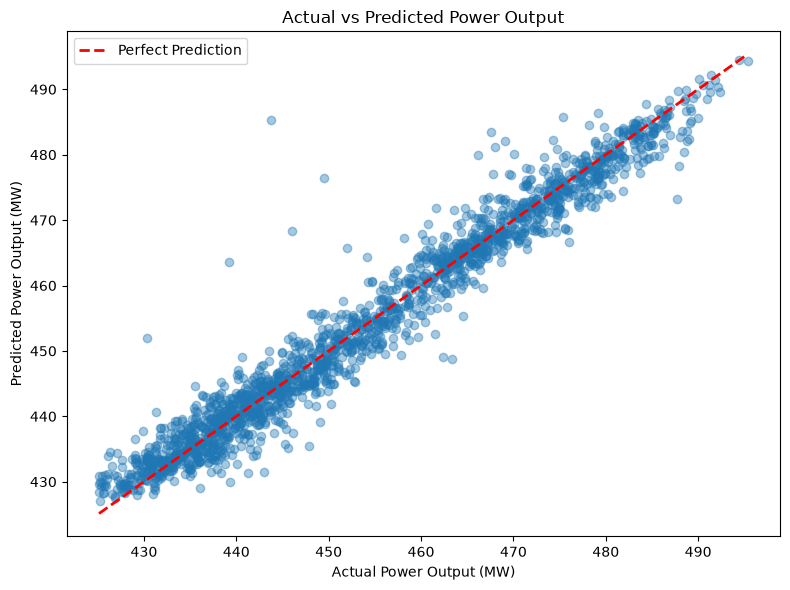

In [51]:
# Plot Actual vs Predicted Power Output

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_best,
    alpha=0.4
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--',
    linewidth=2,
    label='Perfect Prediction'
)

plt.title('Actual vs Predicted Power Output')
plt.xlabel('Actual Power Output (MW)')
plt.ylabel('Predicted Power Output (MW)')
plt.legend()

plt.tight_layout()
plt.show()

### Interpretation

The Actual vs Predicted scatter plot shows a strong agreement between the actual and predicted electrical power output values.

Most data points are closely distributed around the diagonal reference line, indicating that the Tuned Random Forest model provides accurate predictions.

A small number of points deviate from the reference line, representing prediction errors. However, the overall alignment demonstrates strong predictive performance.

These results are consistent with the high R² score of approximately 0.96 obtained during model evaluation.

# 3.10 Residual Analysis

Residual analysis is performed to evaluate the errors made by the Tuned Random Forest model.

Residuals are calculated as the difference between actual and predicted power output values.

The residual distribution helps identify patterns, biases and variations in prediction errors.

In [52]:
# Calculate residuals

residuals = y_test.values - y_pred_best

print("Mean Residual:", np.mean(residuals))
print("Residual Standard Deviation:", np.std(residuals))

Mean Residual: -0.014268175956445644
Residual Standard Deviation: 3.4381718314297025


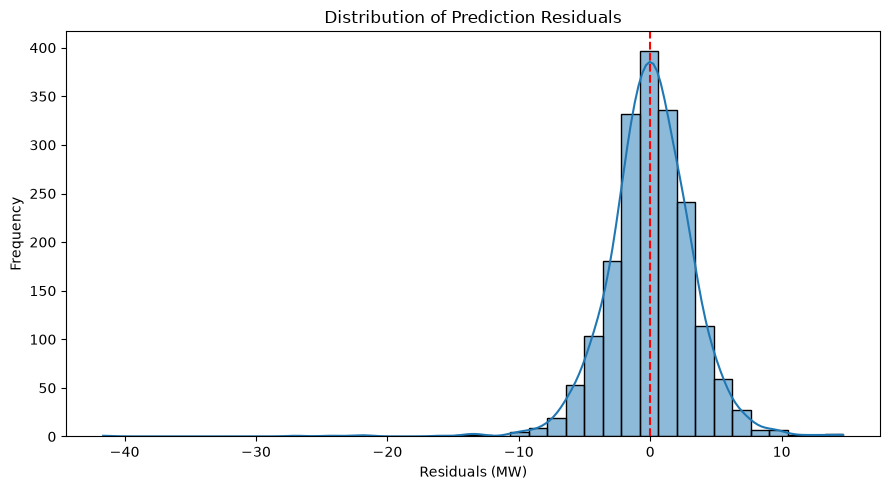

In [53]:
plt.figure(figsize=(9, 5))

sns.histplot(residuals, bins=40, kde=True)

plt.axvline(0, color='red', linestyle='--')

plt.title('Distribution of Prediction Residuals')
plt.xlabel('Residuals (MW)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

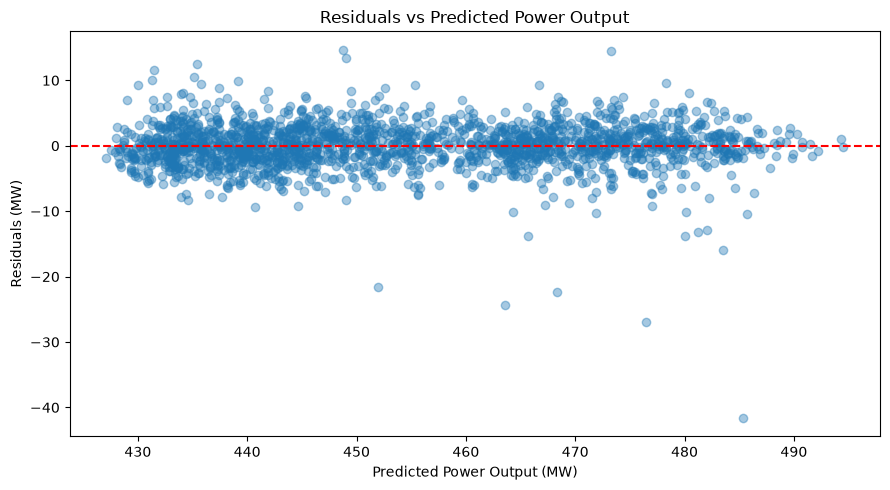

In [54]:
plt.figure(figsize=(9, 5))

plt.scatter(y_pred_best, residuals, alpha=0.4)

plt.axhline(0, color='red', linestyle='--')

plt.title('Residuals vs Predicted Power Output')
plt.xlabel('Predicted Power Output (MW)')
plt.ylabel('Residuals (MW)')

plt.tight_layout()
plt.show()

### Interpretation

The residual distribution shows that most prediction errors are concentrated around zero, indicating that the Tuned Random Forest model generally produces accurate predictions.

The distribution is approximately bell-shaped, although a few extreme negative residuals are present.

The Residuals vs Predicted plot shows that most points are randomly distributed around the zero reference line, suggesting that the model does not exhibit a strong systematic prediction bias.

However, a few large residuals and variations in the spread of errors indicate that some predictions are less accurate than others.

Overall, the residual analysis supports the good predictive performance of the Tuned Random Forest model.

# 3.11 Final Model Evaluation

The Tuned Random Forest model is selected as the final model based on its performance across the evaluated regression metrics.

Its predictive performance is assessed using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² Score.

In [55]:
# Final model evaluation

final_mae = mean_absolute_error(y_test, y_pred_best)

final_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_best)
)

final_r2 = r2_score(y_test, y_pred_best)

final_results = pd.DataFrame({
    'Metric': ['MAE', 'RMSE', 'R2 Score'],
    'Value': [final_mae, final_rmse, final_r2]
})

display(final_results)

,Metric,Value
0,MAE,2.41
1,RMSE,3.44
2,R2 Score,0.96


In [56]:
# Final model evaluation

final_mae = mean_absolute_error(y_test, y_pred_best)

final_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_best)
)

final_r2 = r2_score(y_test, y_pred_best)

final_results = pd.DataFrame({
    'Metric': ['MAE', 'RMSE', 'R2 Score'],
    'Value': [final_mae, final_rmse, final_r2]
})

display(final_results)

,Metric,Value
0,MAE,2.41
1,RMSE,3.44
2,R2 Score,0.96


### Final Evaluation and Conclusion

The Tuned Random Forest model demonstrates strong predictive performance on the unseen test dataset.

It achieves a Mean Absolute Error (MAE) of 2.41 MW, a Root Mean Squared Error (RMSE) of 3.44 MW and an R² score of 0.96.

The high R² score indicates that the model explains approximately 96% of the variation in electrical power output.

The Actual vs Predicted plot and residual analysis further support the model's predictive capability.

Therefore, the Tuned Random Forest model is selected as the final model for predicting electrical power output using environmental parameters.

## 4. Model Export and Packaging

The final Tuned Random Forest model is saved using Joblib so that it can be reused in an external application without requiring retraining.

The saved model will be loaded by the Streamlit application to generate predictions for new input data.

In [57]:
import joblib
import os
import json

# Create models directory if it doesn't exist
os.makedirs("../models", exist_ok=True)

# Save the trained model pipeline
joblib.dump(best_rf, "../models/ccpp_model.joblib")

# Save evaluation metrics
final_metrics = {
    "MAE": float(final_mae),
    "RMSE": float(final_rmse),
    "R2 Score": float(final_r2)
}

with open("../models/model_metrics.json", "w") as f:
    json.dump(final_metrics, f, indent=4)

print("Model saved successfully!")
print("Evaluation metrics saved successfully!")

Model saved successfully!
Evaluation metrics saved successfully!
